# 04 · Broadcasting

**Module 02 — NumPy & Numerical Computing**

---

## What you will learn

1. The two rules that fully determine whether two shapes are compatible.
2. How to read — and fix — a broadcasting error message.
3. `np.newaxis` / `reshape` to make your intent explicit.
4. The silent bug: shapes that broadcast but produce the wrong thing.
5. Real applications: standardising features, pairwise distances, one-hot encoding.
6. The memory trap, and how `einsum` and chunking avoid it.

**Estimated time:** 75 minutes

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dstoolkit import format_bytes, setup_plot_style
from dstoolkit.plotting import COLORS

setup_plot_style()
rng = np.random.default_rng(seed=42)

## 1. The rules

Broadcasting lets NumPy combine arrays of different shapes without you writing
a loop or materialising a copy. There are exactly two rules.

![Broadcasting: the two rules](../../../assets/images/broadcasting_rules.png)

1. **Align the shapes from the right.** If one is shorter, pad it on the **left**
   with 1s.
2. **Two dimensions are compatible if they are equal, or if one of them is 1.**
   A dimension of size 1 is *stretched* to match the other.

If any pair fails rule 2, the operation raises.

In [2]:
# The simplest case: a scalar broadcasts against anything.
arr = np.array([1, 2, 3, 4])
print(f"arr + 10   : {arr + 10}")
print(f"arr * 2    : {arr * 2}")

# A scalar is conceptually shape (), padded to (1,), then stretched to (4,).
print(f"\nnp.broadcast_shapes((4,), ()) → {np.broadcast_shapes((4,), ())}")

arr + 10   : [11 12 13 14]
arr * 2    : [2 4 6 8]

np.broadcast_shapes((4,), ()) → (4,)


In [3]:
# The everyday case: a (3, 4) matrix and a (4,) row.
matrix = np.arange(12).reshape(3, 4)
row = np.array([10, 20, 30, 40])

print(f"matrix shape {matrix.shape}, row shape {row.shape}")
print(f"\nmatrix:\n{matrix}")
print(f"\nmatrix + row:\n{matrix + row}")
print("\n↑ (4,) padded to (1, 4), then stretched down to (3, 4).")
print("  Every row got the same vector added.")

matrix shape (3, 4), row shape (4,)

matrix:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

matrix + row:
[[10 21 32 43]
 [14 25 36 47]
 [18 29 40 51]]

↑ (4,) padded to (1, 4), then stretched down to (3, 4).
  Every row got the same vector added.


### Checking compatibility without running the operation

`np.broadcast_shapes` answers "will these combine, and into what?" — useful when
debugging, and cheap because it allocates nothing.

In [4]:
pairs = [
    ((3, 4), (4,)),
    ((3, 4), (3, 1)),
    ((3, 1), (1, 4)),
    ((2, 3, 4), (3, 4)),
    ((5, 1, 3), (4, 3)),
    ((3, 4), (3,)),        # fails
    ((2, 3), (3, 2)),      # fails
]

print(f"{'shape A':<14} {'shape B':<10} {'result':>12}")
print("-" * 40)
for shape_a, shape_b in pairs:
    try:
        result = np.broadcast_shapes(shape_a, shape_b)
        print(f"{str(shape_a):<14} {str(shape_b):<10} {str(result):>12}")
    except ValueError:
        print(f"{str(shape_a):<14} {str(shape_b):<10} {'INCOMPATIBLE':>12}")

shape A        shape B          result
----------------------------------------
(3, 4)         (4,)             (3, 4)
(3, 4)         (3, 1)           (3, 4)
(3, 1)         (1, 4)           (3, 4)
(2, 3, 4)      (3, 4)        (2, 3, 4)
(5, 1, 3)      (4, 3)        (5, 4, 3)
(3, 4)         (3,)       INCOMPATIBLE
(2, 3)         (3, 2)     INCOMPATIBLE


## 2. Reading the error message

NumPy's broadcasting error is precise once you know how to parse it.

In [5]:
a = np.arange(12).reshape(3, 4)
b = np.array([1, 2, 3])

try:
    a + b
except ValueError as exc:
    print(f"ValueError: {exc}")

ValueError: operands could not be broadcast together with shapes (3,4) (3,) 


Decode it:

- `operands could not be broadcast together` — rule 2 failed.
- `with shapes (3,4) (3,)` — the two inputs.

Align them from the right, as NumPy does:

```text
(3, 4)
   (3)   →  padded to (1, 3)
─────────
 4 vs 3  →  neither is 1  →  fail
```

The intent was almost certainly "add one value per **row**", which means `b`
needs to be a **column**:

In [6]:
print(f"b as a column, shape {b.reshape(-1, 1).shape}:\n{b.reshape(-1, 1)}")
print(f"\na + b.reshape(-1, 1):\n{a + b.reshape(-1, 1)}")
print("\n↑ each row got its own value — one per row, as intended.")

b as a column, shape (3, 1):
[[1]
 [2]
 [3]]

a + b.reshape(-1, 1):
[[ 1  2  3  4]
 [ 6  7  8  9]
 [11 12 13 14]]

↑ each row got its own value — one per row, as intended.


## 3. Making intent explicit with `np.newaxis`

`np.newaxis` (an alias for `None`) inserts a dimension of size 1. It is the
clearest way to say "treat this as a row" or "treat this as a column".

In [7]:
v = np.array([1, 2, 3])

print(f"v                  shape {v.shape}")
print(f"v[np.newaxis, :]   shape {v[np.newaxis, :].shape}   ← a ROW")
print(f"v[:, np.newaxis]   shape {v[:, np.newaxis].shape}   ← a COLUMN")
print(f"v[:, None]         shape {v[:, None].shape}   ← same, shorter")

v                  shape (3,)
v[np.newaxis, :]   shape (1, 3)   ← a ROW
v[:, np.newaxis]   shape (3, 1)   ← a COLUMN
v[:, None]         shape (3, 1)   ← same, shorter


In [8]:
# The classic outer-product pattern: column ⊗ row → matrix.
column = v[:, None]      # (3, 1)
row = v[None, :]         # (1, 3)

print(f"column * row  →  shape {(column * row).shape}\n{column * row}")
print(f"\nmatches np.outer : {np.array_equal(column * row, np.outer(v, v))}")

column * row  →  shape (3, 3)
[[1 2 3]
 [2 4 6]
 [3 6 9]]

matches np.outer : True


## 4. The silent bug

The dangerous case is not the one that raises. It is the one that **broadcasts
successfully into a shape you did not intend**.

In [9]:
predictions = np.array([1.0, 2.0, 3.0, 4.0])       # shape (4,)
actuals = np.array([[1.1], [2.1], [2.9], [4.2]])   # shape (4, 1) — a column!

errors = predictions - actuals

print(f"predictions shape : {predictions.shape}")
print(f"actuals shape     : {actuals.shape}")
print(f"errors shape      : {errors.shape}   ← expected (4,), got a 4×4 matrix")
print(f"\nerrors:\n{errors.round(2)}")

mse_wrong = (errors**2).mean()
mse_right = ((predictions - actuals.ravel()) ** 2).mean()

print(f"\nMSE from the accidental matrix : {mse_wrong:.4f}")
print(f"MSE computed correctly         : {mse_right:.4f}")
print(f"→ inflated by {mse_wrong / mse_right:.1f}×, with no error raised")

predictions shape : (4,)
actuals shape     : (4, 1)
errors shape      : (4, 4)   ← expected (4,), got a 4×4 matrix

errors:
[[-0.1  0.9  1.9  2.9]
 [-1.1 -0.1  0.9  1.9]
 [-1.9 -0.9  0.1  1.1]
 [-3.2 -2.2 -1.2 -0.2]]

MSE from the accidental matrix : 2.5425
MSE computed correctly         : 0.0175
→ inflated by 145.3×, with no error raised


> [!WARNING]
> This is the most common broadcasting bug in machine-learning code, and it
> usually arrives as a `(n, 1)` column from `reshape(-1, 1)` or from a
> DataFrame column meeting a 1-D prediction array. Nothing raises; the loss is
> simply wrong.

**The defence: assert the shape you expect.**

In [10]:
def mean_squared_error(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Mean squared error, with a shape guard that makes the bug impossible.

    Raises
    ------
    ValueError
        If the inputs do not have identical shapes after flattening.
    """
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    if y_true.shape != y_pred.shape:
        raise ValueError(
            f"shape mismatch: y_true {y_true.shape} vs y_pred {y_pred.shape}"
        )

    return float(((y_true - y_pred) ** 2).mean())


print(f"guarded MSE : {mean_squared_error(actuals, predictions):.4f}")

try:
    mean_squared_error(np.zeros(4), np.zeros(5))
except ValueError as exc:
    print(f"caught      : {exc}")

guarded MSE : 0.0175
caught      : shape mismatch: y_true (4,) vs y_pred (5,)


## 5. Real applications

### Standardising features — the operation behind `StandardScaler`

In [11]:
# 1000 samples, 4 features, deliberately on wildly different scales.
X = rng.normal(loc=[0, 100, -50, 1000], scale=[1, 25, 10, 200], size=(1000, 4))

print(f"X shape        : {X.shape}")
print(f"column means   : {X.mean(axis=0).round(2)}")
print(f"column stds    : {X.std(axis=0).round(2)}")

# mean and std are shape (4,); X is (1000, 4).
# (4,) pads to (1, 4) and stretches down all 1000 rows — exactly right.
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print(f"\nafter scaling:")
print(f"  means : {X_scaled.mean(axis=0).round(6)}")
print(f"  stds  : {X_scaled.std(axis=0).round(6)}")

X shape        : (1000, 4)
column means   : [-2.0000e-02  9.9890e+01 -5.0410e+01  9.9664e+02]
column stds    : [  0.98  24.97  10.1  202.61]

after scaling:
  means : [ 0. -0. -0. -0.]
  stds  : [1. 1. 1. 1.]


> [!TIP]
> Note that `axis=0` is what makes this work: it collapses the **rows**,
> leaving one statistic per column. Get the axis wrong and you would normalise
> each sample against itself — which broadcasts fine and is meaningless.
> Notebook 05 covers axis semantics in depth.

In [12]:
# The wrong axis broadcasts too — and silently produces nonsense.
try:
    wrong = (X - X.mean(axis=1)) / X.std(axis=1)
    print(f"axis=1 result shape : {wrong.shape}")
except ValueError as exc:
    print(f"axis=1 raises : {exc}")
    print("\nHere we got lucky — the shapes were incompatible so it failed loudly.")
    print("With a square matrix it would have broadcast silently.")

axis=1 raises : operands could not be broadcast together with shapes (1000,4) (1000,) 

Here we got lucky — the shapes were incompatible so it failed loudly.
With a square matrix it would have broadcast silently.


### Pairwise distances without a loop

A staple of clustering, nearest neighbours, and recommender systems.

In [13]:
points = rng.random((5, 2)) * 10

# points[:, None, :] has shape (5, 1, 2)
# points[None, :, :] has shape (1, 5, 2)
# Broadcasting gives (5, 5, 2): every point against every other point.
differences = points[:, None, :] - points[None, :, :]
distances = np.sqrt((differences**2).sum(axis=-1))

print(f"points shape      : {points.shape}")
print(f"differences shape : {differences.shape}   ← (i, j, coordinate)")
print(f"distances shape   : {distances.shape}   ← (i, j)")
print(f"\ndistance matrix:\n{distances.round(2)}")

# Sanity checks that should always hold for a distance matrix.
print(f"\ndiagonal is zero : {np.allclose(np.diag(distances), 0)}")
print(f"symmetric        : {np.allclose(distances, distances.T)}")

points shape      : (5, 2)
differences shape : (5, 5, 2)   ← (i, j, coordinate)
distances shape   : (5, 5)   ← (i, j)

distance matrix:
[[0.   4.77 7.46 3.44 3.41]
 [4.77 0.   2.99 2.98 3.18]
 [7.46 2.99 0.   4.63 6.13]
 [3.44 2.98 4.63 0.   4.41]
 [3.41 3.18 6.13 4.41 0.  ]]

diagonal is zero : True
symmetric        : True


In [14]:
# Verify against SciPy's implementation.
from scipy.spatial.distance import cdist

print(f"matches scipy.cdist : {np.allclose(distances, cdist(points, points))}")

matches scipy.cdist : True


### One-hot encoding in one line

In [15]:
labels = np.array([0, 2, 1, 2, 0, 1])
n_classes = labels.max() + 1

# labels[:, None] is (6, 1); arange(3) is (3,) → (1, 3).
# Broadcasting compares every label against every class index.
one_hot = (labels[:, None] == np.arange(n_classes)).astype(np.int8)

print(f"labels   : {labels}")
print(f"one-hot  :\n{one_hot}")
print(f"\nshape    : {one_hot.shape}   (n_samples, n_classes)")
print(f"one 1 per row : {np.array_equal(one_hot.sum(axis=1), np.ones(len(labels)))}")

labels   : [0 2 1 2 0 1]
one-hot  :
[[1 0 0]
 [0 0 1]
 [0 1 0]
 [0 0 1]
 [1 0 0]
 [0 1 0]]

shape    : (6, 3)   (n_samples, n_classes)
one 1 per row : True


## 6. The memory trap

Broadcasting does **not** materialise the stretched array — that is the whole
point. But the **result** is fully materialised, and it can be enormous.

In [16]:
a = np.arange(10_000, dtype=np.float64)      # 10k elements, 80 KB
b = np.arange(10_000, dtype=np.float64)

result_shape = np.broadcast_shapes(a[:, None].shape, b[None, :].shape)
result_bytes = np.prod(result_shape) * 8

print(f"a         : {format_bytes(a.nbytes)}")
print(f"b         : {format_bytes(b.nbytes)}")
print(f"a[:, None] - b[None, :] → shape {result_shape}")
print(f"result    : {format_bytes(result_bytes)}   ← from two 80 KB inputs")

a         : 78.1 KiB
b         : 78.1 KiB
a[:, None] - b[None, :] → shape (10000, 10000)
result    : 762.9 MiB   ← from two 80 KB inputs


Two small arrays produced a result nearly a thousand times larger. Scale the
inputs to 100 000 and the result would be 80 GB — an instant `MemoryError`.

In [17]:
# When you only need a REDUCTION of the big intermediate, avoid building it.
# Example: the sum of all pairwise products.

small_a = np.arange(2_000, dtype=np.float64)
small_b = np.arange(2_000, dtype=np.float64)

# ✘ Materialises a 2000×2000 intermediate (32 MB) to then collapse it.
naive = (small_a[:, None] * small_b[None, :]).sum()

# ✔ Algebra: Σᵢ Σⱼ aᵢbⱼ = (Σᵢ aᵢ)(Σⱼ bⱼ). No intermediate at all.
smart = small_a.sum() * small_b.sum()

print(f"naive result : {naive:,.0f}")
print(f"smart result : {smart:,.0f}")
print(f"identical    : {np.isclose(naive, smart)}")
print(f"\nintermediate avoided : "
      f"{format_bytes(2_000 * 2_000 * 8)}")

naive result : 3,996,001,000,000
smart result : 3,996,001,000,000
identical    : True

intermediate avoided : 30.5 MiB


### `np.einsum` — reductions without the intermediate

Einstein summation expresses "multiply these axes and sum over that one" in a
single pass, without building the full outer product.

In [18]:
A = rng.random((500, 300))
B = rng.random((300, 400))

# These agree, but einsum lets you express contractions that have no
# matmul equivalent, and it fuses the multiply and the sum.
via_matmul = A @ B
via_einsum = np.einsum("ij,jk->ik", A, B)

print(f"matmul and einsum agree : {np.allclose(via_matmul, via_einsum)}")

# A contraction that is awkward otherwise: row-wise dot product of two matrices.
P = rng.random((1000, 50))
Q = rng.random((1000, 50))

row_dots_naive = (P * Q).sum(axis=1)          # builds a (1000, 50) intermediate
row_dots_einsum = np.einsum("ij,ij->i", P, Q)  # no intermediate

print(f"row-wise dots agree     : {np.allclose(row_dots_naive, row_dots_einsum)}")
print(f"result shape            : {row_dots_einsum.shape}")

matmul and einsum agree : True
row-wise dots agree     : True
result shape            : (1000,)


### Chunking when the intermediate is unavoidable

In [19]:
def pairwise_distances_chunked(
    X: np.ndarray, chunk_size: int = 500
) -> np.ndarray:
    """Pairwise Euclidean distances, computed a block of rows at a time.

    Peak memory is ``chunk_size × n_samples`` rather than ``n_samples²``, which
    is what makes this feasible on data that would otherwise not fit.
    """
    n = X.shape[0]
    out = np.empty((n, n), dtype=X.dtype)

    for start in range(0, n, chunk_size):
        stop = min(start + chunk_size, n)
        block = X[start:stop, None, :] - X[None, :, :]
        out[start:stop] = np.sqrt((block**2).sum(axis=-1))

    return out


sample = rng.random((1_200, 3))

chunked = pairwise_distances_chunked(sample, chunk_size=300)
reference = cdist(sample, sample)

print(f"shape            : {chunked.shape}")
print(f"matches scipy    : {np.allclose(chunked, reference)}")
print(f"full intermediate would be : "
      f"{format_bytes(1_200 * 1_200 * 3 * 8)}")
print(f"chunked peak is  : {format_bytes(300 * 1_200 * 3 * 8)}")

shape            : (1200, 1200)


matches scipy    : True
full intermediate would be : 33.0 MiB
chunked peak is  : 8.2 MiB


## 7. Visualising a broadcast

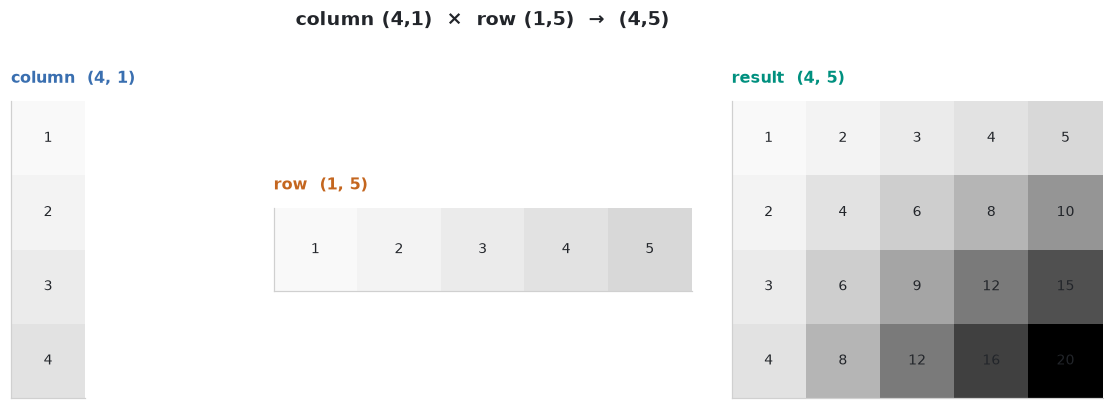

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

column = np.arange(1, 5).reshape(4, 1)
row_vec = np.arange(1, 6).reshape(1, 5)
product = column * row_vec

panels = [
    (column, f"column  {column.shape}", COLORS["primary"]),
    (row_vec, f"row  {row_vec.shape}", COLORS["accent"]),
    (product, f"result  {product.shape}", COLORS["teal"]),
]

for ax, (data, title, color) in zip(axes, panels, strict=True):
    ax.imshow(data, cmap="Greys", vmin=0, vmax=product.max(), aspect="equal")
    ax.set_title(title, fontsize=10.5, color=color, fontweight="bold")

    # Print the value in each cell — with only 20 cells, the numbers ARE the data.
    for (i, j), value in np.ndenumerate(data):
        ax.text(j, i, str(value), ha="center", va="center", fontsize=9,
                color=COLORS["text"])

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

fig.suptitle("column (4,1)  ×  row (1,5)  →  (4,5)", fontsize=12.5, y=1.02)
fig.tight_layout()
plt.show()

## 8. Exercises

### Exercise 4.1 — Compatible or not?

For each pair, state the result shape or "incompatible", then check with
`np.broadcast_shapes`:

```
(5, 4)    and (4,)          (5, 4)    and (5,)
(5, 4)    and (5, 1)        (3, 1, 4) and (2, 4)
(2, 3, 4) and (3, 1)        (8, 1, 6) and (7, 1)
```

### Exercise 4.2 — Fix the silent bug

```python
y_true = np.array([[1.0], [2.0], [3.0]])
y_pred = np.array([1.1, 1.9, 3.2])
residuals = y_true - y_pred
```

What shape is `residuals`, and what should it be? Fix it, and add an assertion
that would have caught it.

### Exercise 4.3 — Normalise rows instead of columns

Given `X` of shape `(100, 5)`, scale each **row** so it sums to 1. Then explain
why `X / X.sum(axis=1)` fails and `X / X.sum(axis=1, keepdims=True)` works.

### Exercise 4.4 — Distance to centroids

You have `X` of shape `(1000, 3)` and `centroids` of shape `(8, 3)`. Using only
broadcasting, compute a `(1000, 8)` matrix of distances, then the index of the
nearest centroid for each point. This is one full iteration of k-means — you
will reuse it in the module project.

### Exercise 4.5 — Avoid the intermediate

`(a[:, None] - b[None, :])**2).sum()` computes the sum of squared differences
between all pairs. For `a` and `b` of 50 000 elements the intermediate is 20 GB.
Expand the algebra and compute the same number using only `sum`, `dot`, and
scalars.

## Key takeaways

- **Align right, pad left with 1s; dimensions must match or be 1.** That is the
  whole of broadcasting.
- Use **`np.broadcast_shapes`** to check compatibility without allocating.
- **`arr[:, None]` makes a column; `arr[None, :]` makes a row.** Say which you
  mean rather than hoping.
- The dangerous case is the one that **succeeds with the wrong shape** — a
  `(n,)` meeting an `(n, 1)` gives an `(n, n)` and no error.
- **Assert your shapes** in any function that computes a metric or a loss.
- Broadcasting does not materialise the inputs, but **it does materialise the
  result** — two 10k vectors make an 800 MB matrix.
- When you only need a reduction, use **algebra**, **`einsum`**, or **chunking**
  instead of building the intermediate.

---

**Next:** [05 · Aggregations & Boolean Masking](05_aggregations_and_masking.ipynb)
— `axis=` demystified, and the indexing tools that replace `if` inside a loop.